In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [ ]:
url = 'https://books.toscrape.com/'

response = requests.get(url)

print(response.status_code)

200


In [ ]:
soup = BeautifulSoup(response.text, 'html.parser')

print(soup.title.text)


    All products | Books to Scrape - Sandbox



In [ ]:
books = soup.find_all('article', class_='product_pod')

print("Number of books:", len(books))

Number of books: 20


In [ ]:
first_book = books[0]

title = first_book.h3.a['title']
price = first_book.find('p', class_='price_color').text
rating = first_book.p['class'][1]

print("Book:", title)
print("Price:", price)
print("Rating:", rating)

Book: A Light in the Attic
Price: Â£51.77
Rating: Three


In [ ]:
titles = []
prices = []
ratings = []

for book in books:
    titles.append(book.h3.a['title'])
    prices.append(book.find('p', class_='price_color').text)
    ratings.append(book.p['class'][1])

print(titles)

['A Light in the Attic', 'Tipping the Velvet', 'Soumission', 'Sharp Objects', 'Sapiens: A Brief History of Humankind', 'The Requiem Red', 'The Dirty Little Secrets of Getting Your Dream Job', 'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull', 'The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics', 'The Black Maria', 'Starving Hearts (Triangular Trade Trilogy, #1)', "Shakespeare's Sonnets", 'Set Me Free', "Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)", 'Rip it Up and Start Again', 'Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991', 'Olio', 'Mesaerion: The Best Science Fiction Stories 1800-1849', 'Libertarianism for Beginners', "It's Only the Himalayas"]


In [7]:
df = pd.DataFrame({
    'Title': titles,
    'Price': prices,
    'Rating': ratings
})

df.head(20)

,Title,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five
5,The Requiem Red,Â£22.65,One
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,Four
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,Three
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,Four
9,The Black Maria,Â£52.15,One


In [9]:
print(df['Price'].head())

0    Â£51.77
1    Â£53.74
2    Â£50.10
3    Â£47.82
4    Â£54.23
Name: Price, dtype: object


In [10]:
df['Price'] = df['Price'].str.replace('Â£', '', regex=False).astype(float)

print("Total books:", len(df))
print("Average price:", df['Price'].mean())

Total books: 20
Average price: 38.048500000000004


In [11]:
print("Highest price:", df['Price'].max())

print("Lowest price:", df['Price'].min())

Highest price: 57.25
Lowest price: 13.99


In [12]:
print(df['Rating'].value_counts())

Rating
One      6
Five     4
Four     4
Three    3
Two      3
Name: count, dtype: int64


In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

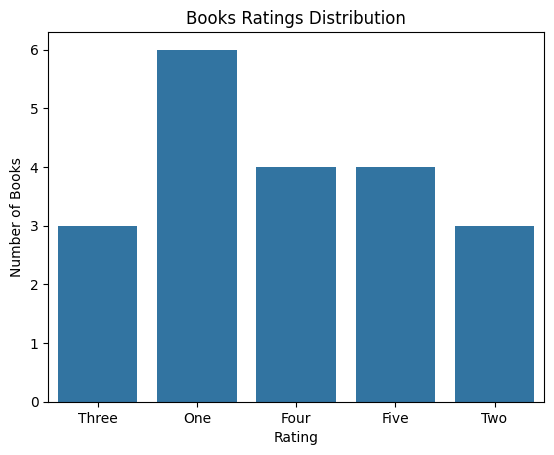

In [15]:
sns.countplot(data=df, x='Rating')

plt.title('Books Ratings Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Books')
plt.show()

In [16]:
df.sort_values(by='Price', ascending=False).head(5)

,Title,Price,Rating
15,Our Band Could Be Your Life: Scenes from the A...,57.25,Three
4,Sapiens: A Brief History of Humankind,54.23,Five
1,Tipping the Velvet,53.74,One
13,Scott Pilgrim's Precious Little Life (Scott Pi...,52.29,Five
9,The Black Maria,52.15,One


In [17]:
df.groupby('Rating')['Price'].mean().sort_values(ascending=False)

,Price
Rating,
Three,42.316667
One,40.018333
Five,39.750000
Two,36.830000
Four,31.105000


In [18]:
next_page = soup.find('li', class_='next')
print(next_page.a['href'])

catalogue/page-2.html


In [19]:
next_url = 'https://books.toscrape.com/catalogue/page-2.html'

response2 = requests.get(next_url)

soup2 = BeautifulSoup(response2.text, 'html.parser')

books2 = soup2.find_all('article', class_='product_pod')

print("Books on page 2:", len(books2))

Books on page 2: 20


In [20]:
for book in books2:
    title = book.h3.a['title']
    price = book.find('p', class_='price_color').text
    rating = book.p['class'][1]

    titles.append(title)
    prices.append(price)
    ratings.append(rating)

print("Total collected books:", len(titles))

Total collected books: 40


In [21]:
df = pd.DataFrame({
    'Title': titles,
    'Price': prices,
    'Rating': ratings
})

df['Price'] = df['Price'].str.replace('Â£', '', regex=False).astype(float)

print("Total books:", len(df))

df.tail(20)

Total books: 40


,Title,Price,Rating
20,In Her Wake,12.84,One
21,How Music Works,37.32,Two
22,Foolproof Preserving: A Guide to Small Batch J...,30.52,Three
23,Chase Me (Paris Nights #2),25.27,Five
24,Black Dust,34.53,Five
25,Birdsong: A Story in Pictures,54.64,Three
26,America's Cradle of Quarterbacks: Western Penn...,22.50,Three
27,Aladdin and His Wonderful Lamp,53.13,Three
28,Worlds Elsewhere: Journeys Around Shakespeareâ...,40.30,Five
29,Wall and Piece,44.18,Four


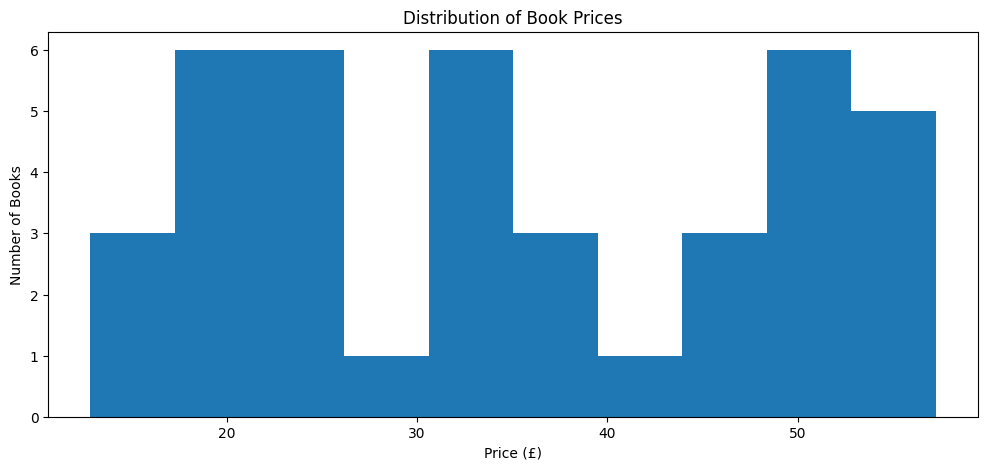

In [22]:
plt.figure(figsize=(12, 5))

plt.hist(df['Price'], bins=10)

plt.title('Distribution of Book Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Books')

plt.show()

In [23]:
print("Average Price:", round(df['Price'].mean(), 2))
print("Maximum Price:", df['Price'].max())
print("Minimum Price:", df['Price'].min())
print("Total Books:", len(df))

Average Price: 34.96
Maximum Price: 57.25
Minimum Price: 12.84
Total Books: 40


Web Scraping: Books to Scrape

Project Overview

This project uses Web Scraping techniques to extract book information from the Books to Scrape website.

Tools and Libraries

- Python
- Requests
- BeautifulSoup
- Pandas
- Matplotlib
- Seaborn

Extracted Data

- Book Titles
- Book Prices
- Book Ratings

Data Analysis

- Number of collected books.
- Average book price.
- Highest and lowest book prices.
- Book rating distribution.
- Price distribution visualization.

Results and Findings

- Successfully extracted 40 books from two website pages.
- Collected book titles, prices, and ratings.
- Calculated the average, maximum, and minimum book prices.
- Visualized book price distribution and ratings.

Conclusion

This project demonstrates how Web Scraping can collect useful data from websites automatically. The extracted data was organized and analyzed using Python libraries.

Future Improvements

The project can be improved by extracting data from all available pages and collecting more book information.